In [ ]:
!pip install -q kagglehub[pandas-datasets]

In [ ]:
import kagglehub
from kagglehub import KaggleDatasetAdapter
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [ ]:
file_path = "Data_Entry_2017.csv"                                                             # exact CSV filename w/in Kaggle dataset
df = kagglehub.dataset_load(KaggleDatasetAdapter.PANDAS, "nih-chest-xrays/data", file_path)   # load CSV into pd DataFrame

100%|██████████| 924k/924k [00:00<00:00, 23.8MB/s]

Extracting zip of Data_Entry_2017.csv...


In [ ]:
# path = kagglehub.dataset_download("nih-chest-xrays/data")                                     # download dataset
# print("Dataset downloaded to:", path)                                                         # get directory where dataset is stored

In [ ]:
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())
display(df.head())

Dataset shape: (112120, 12)

Columns:
['Image Index', 'Finding Labels', 'Follow-up #', 'Patient ID', 'Patient Age', 'Patient Gender', 'View Position', 'OriginalImage[Width', 'Height]', 'OriginalImagePixelSpacing[x', 'y]', 'Unnamed: 11']


,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Gender,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y],Unnamed: 11
0,00000001_000.png,Cardiomegaly,0,1,58,M,PA,2682,2749,0.143,0.143,NaN
1,00000001_001.png,Cardiomegaly|Emphysema,1,1,58,M,PA,2894,2729,0.143,0.143,NaN
2,00000001_002.png,Cardiomegaly|Effusion,2,1,58,M,PA,2500,2048,0.168,0.168,NaN
3,00000002_000.png,No Finding,0,2,81,M,PA,2500,2048,0.171,0.171,NaN
4,00000003_000.png,Hernia,0,3,81,F,PA,2582,2991,0.143,0.143,NaN


In [ ]:
# SIMPLE DATASET STATS
print(f"Number of images: {len(df):,}")                                         # length = num of images
print(f"Number of unique patients: {df['Patient ID'].nunique():,}")             # .nunique() counts num of unique vals, use patient ID to determine num of patients

Number of images: 112,120
Number of unique patients: 30,805


In [ ]:
# EXPLORE DISEASES
DISEASES = ["Atelectasis", "Cardiomegaly", "Consolidation", "Edema", "Effusion", "Emphysema", "Fibrosis", "Hernia",
            "Infiltration", "Mass", "Nodule", "Pleural Thickening", "Pneumonia", "Pneumothorax"]

all_labels = set()                                      # split pipe-separated labels into individual labels (multiple labels separated by | w/in dataset)

for labels in df["Finding Labels"]:                     # go through "Finding Labels" col for every img to split disease labels into individual labels
    for label in labels.split("|"):
        all_labels.add(label)                           # add each individual label to set

print("Labels found in dataset:")
for label in sorted(all_labels):                        # use sorted() to make output easier to read lol
    print(label)

Labels found in dataset:
Atelectasis
Cardiomegaly
Consolidation
Edema
Effusion
Emphysema
Fibrosis
Hernia
Infiltration
Mass
No Finding
Nodule
Pleural_Thickening
Pneumonia
Pneumothorax


In [ ]:
# "NO FINDING" IMAGES
no_finding_count = (df["Finding Labels"] == "No Finding").sum()     # imgs where none of 14 diseases were assigned (T/F for every row, sum() counts T vals)
print(f"No Finding images: {no_finding_count:,}")
print(f"Percentage: {no_finding_count/len(df) * 100:.2f}%")         # percent of dataset that "No Finding" represents

No Finding images: 60,361
Percentage: 53.84%


In [ ]:
# HOW MANY DISASES EACH IMG HAS
def get_disease_labels(label_string):                                                       # function to convert "finding labels" col into list containing only actual disease labels
    labels = label_string.split("|")                                                        # split pipe-separated string into individual labels
    return [label for label in labels if label != "No Finding"]                             # remove "no finding" bc not a disease (note that 0 = no finding)

df["Disease Labels"] = df["Finding Labels"].apply(get_disease_labels)                       # apply function to every row in df, create new col called "disease labels"
df["Num Diseases"] = df["Disease Labels"].apply(len)                                        # count num diseases presenting each img, create new col called "num diseases"
display(df[["Image Index", "Finding Labels", "Disease Labels", "Num Diseases"]].head(10))   # display first 10 rows

,Image Index,Finding Labels,Disease Labels,Num Diseases
0,00000001_000.png,Cardiomegaly,[Cardiomegaly],1
1,00000001_001.png,Cardiomegaly|Emphysema,"[Cardiomegaly, Emphysema]",2
2,00000001_002.png,Cardiomegaly|Effusion,"[Cardiomegaly, Effusion]",2
3,00000002_000.png,No Finding,[],0
4,00000003_000.png,Hernia,[Hernia],1
5,00000003_001.png,Hernia,[Hernia],1
6,00000003_002.png,Hernia,[Hernia],1
7,00000003_003.png,Hernia|Infiltration,"[Hernia, Infiltration]",2
8,00000003_004.png,Hernia,[Hernia],1
9,00000003_005.png,Hernia,[Hernia],1


In [ ]:
# COUNT NUM DISEASES PER IMG
disease_count_distribution = (df["Num Diseases"].value_counts().sort_index())   # value_counts() counts how frequent each num is, sort_index() puts in numerical order
print(disease_count_distribution)

print("\nNumber of diseases per image:")

for n in [0, 1, 2, 3, 4]:                                                       # count imgs with 0 - 4 diseases
    count = (df["Num Diseases"] == n).sum()
    print(f"{n} diseases: {count:,}")

five_plus = (df["Num Diseases"] >= 5).sum()                                     # separately count imgs wih 5 or more diseases
print(f"5+ diseases: {five_plus:,}")

Num Diseases
0    60361
1    30963
2    14306
3     4856
4     1247
5      301
6       67
7       16
8        1
9        2
Name: count, dtype: int64

Number of diseases per image:
0 diseases: 60,361
1 diseases: 30,963
2 diseases: 14,306
3 diseases: 4,856
4 diseases: 1,247
5+ diseases: 387


In [ ]:
# DISEASE CLASS DISTRIBUTION
class_distribution = []                                                                                               # store results in list

for disease in DISEASES:                                                                                              # for ever img, check if disease is present, go through all 14 diseases
    count = df["Disease Labels"].apply(lambda labels: disease in labels).sum()                                        # sum() counts how many T vals there are
    percentage = count/len(df) * 100                                                                                  # percent of all imgs containing this disease

    class_distribution.append({                                                                                       # store results in dict
        "Disease": disease,
        "# Images": count,
        "% of Dataset": percentage
    })

class_distribution_df = pd.DataFrame(class_distribution)                                                              # convert list of dicts into df
class_distribution_df = (class_distribution_df.sort_values("# Images", ascending = False).reset_index(drop = True))   # sort from most common to least common disease
print(class_distribution_df)

               Disease  # Images  % of Dataset
0         Infiltration     19894     17.743489
1             Effusion     13317     11.877453
2          Atelectasis     11559     10.309490
3               Nodule      6331      5.646629
4                 Mass      5782      5.156975
5         Pneumothorax      5302      4.728862
6        Consolidation      4667      4.162504
7         Cardiomegaly      2776      2.475919
8            Emphysema      2516      2.244024
9                Edema      2303      2.054049
10            Fibrosis      1686      1.503746
11           Pneumonia      1431      1.276311
12              Hernia       227      0.202462
13  Pleural Thickening         0      0.000000


In [ ]:
# BINARY DISEASE MATRIX
# convert multi-label disease info into binary matrix, use matrix to see which disease tend to appear together in same X-ray img, helps to identify potential diseases to exclude from training

disease_cols = ["Atelectasis", "Cardiomegaly", "Consolidation", "Edema", "Effusion", "Emphysema", "Fibrosis",       # excluding "no finding" b/c not positive disease category
                "Hernia", "Infiltration", "Mass", "Nodule", "Pleural Thickening", "Pneumonia", "Pneumothorax"]

labels_in_data = {label for labels in df["Disease Labels"] for label in labels}
missing_labels = set(disease_cols) - labels_in_data                                                                 # verify every disease appears w/in parsed labels

binary_matrix = pd.DataFrame({disease: df["Disease Labels"].apply(lambda labels: int(disease in labels))            # create one col per disease, each row corresponds to same img row in df
                            for disease in disease_cols}, index = df.index)                                         # for every img: 1 = present and 0 = not present

print("Matrix shape:", binary_matrix.shape)                                                                         # should be num of imgs, i.e., 14 disease cols
display(binary_matrix.head())                                                                                       # print first five rows

print("\nNumber of positive images per disease:")                                                                   # note that, b/c labels are multi-label, disease counts overlap
print(binary_matrix.sum().sort_values(ascending = False))

prevalence = binary_matrix.sum().sort_values(ascending = False)                                                     # sum each col of matrix, sum equals num of imgs labeled w/ that disease
prevalence_proportion = binary_matrix.mean().reindex(prevalence.index)                                              # convert counts to proporttions of all imgs (e.g, 0.2 mean 20% of imgs have that disease label)

print("\nDisease Prevalence:")
display(pd.DataFrame({"Image Count": prevalence, "Percentage of Images": prevalence_proportion * 100}).round(2))

Matrix shape: (112120, 14)


,Atelectasis,Cardiomegaly,Consolidation,Edema,Effusion,Emphysema,Fibrosis,Hernia,Infiltration,Mass,Nodule,Pleural Thickening,Pneumonia,Pneumothorax
0,0,1,0,0,0,0,0,0,0,0,0,0,0,0
1,0,1,0,0,0,1,0,0,0,0,0,0,0,0
2,0,1,0,0,1,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,1,0,0,0,0,0,0



Number of positive images per disease:
Infiltration          19894
Effusion              13317
Atelectasis           11559
Nodule                 6331
Mass                   5782
Pneumothorax           5302
Consolidation          4667
Cardiomegaly           2776
Emphysema              2516
Edema                  2303
Fibrosis               1686
Pneumonia              1431
Hernia                  227
Pleural Thickening        0
dtype: int64

Disease Prevalence:


,Image Count,Percentage of Images
Infiltration,19894,17.74
Effusion,13317,11.88
Atelectasis,11559,10.31
Nodule,6331,5.65
Mass,5782,5.16
Pneumothorax,5302,4.73
Consolidation,4667,4.16
Cardiomegaly,2776,2.48
Emphysema,2516,2.24
Edema,2303,2.05


In [ ]:
# CO-OCCURRENCE ANALYSIS
co_occurrence = binary_matrix.T.dot(binary_matrix)                            # count how many imgs contain each pair of diseases, compare every disease w/ every other disease, diagonal = each disease's total img count

print("\nJoint disease co-occurrence counts:")
display(co_occurrence)

row_prevalence = binary_matrix.sum(axis = 0)                                  # given img has disease A, how often does it also have disease B? (rows = conditioning disease A, col = accompanying disease B)
conditional = co_occurrence.div(row_prevalence.replace(0, np.nan), axis = 0)  # P(B | A) = N(A and B) / N(A), divide each row by num of imgs containing that row's disease, replace(0, np.nan) avoids dividing by zero

print("\nConditional probabilities P(B | A):")
display(conditional.round(3))


Joint disease co-occurrence counts:


,Atelectasis,Cardiomegaly,Consolidation,Edema,Effusion,Emphysema,Fibrosis,Hernia,Infiltration,Mass,Nodule,Pleural Thickening,Pneumonia,Pneumothorax
Atelectasis,11559,370,1223,221,3275,424,220,40,3264,739,590,0,262,774
Cardiomegaly,370,2776,169,127,1063,44,52,7,587,102,108,0,41,49
Consolidation,1223,169,4667,162,1287,103,79,4,1221,610,428,0,123,223
Edema,221,127,162,2303,593,30,9,3,981,129,131,0,340,33
Effusion,3275,1063,1287,593,13317,359,188,21,4000,1254,912,0,269,996
Emphysema,424,44,103,30,359,2516,36,4,449,215,115,0,23,747
Fibrosis,220,52,79,9,188,36,1686,8,345,117,166,0,11,80
Hernia,40,7,4,3,21,4,8,227,33,25,10,0,3,9
Infiltration,3264,587,1221,981,4000,449,345,33,19894,1159,1546,0,605,946
Mass,739,102,610,129,1254,215,117,25,1159,5782,906,0,71,431



Conditional probabilities P(B | A):


,Atelectasis,Cardiomegaly,Consolidation,Edema,Effusion,Emphysema,Fibrosis,Hernia,Infiltration,Mass,Nodule,Pleural Thickening,Pneumonia,Pneumothorax
Atelectasis,1.000,0.032,0.106,0.019,0.283,0.037,0.019,0.003,0.282,0.064,0.051,0.0,0.023,0.067
Cardiomegaly,0.133,1.000,0.061,0.046,0.383,0.016,0.019,0.003,0.211,0.037,0.039,0.0,0.015,0.018
Consolidation,0.262,0.036,1.000,0.035,0.276,0.022,0.017,0.001,0.262,0.131,0.092,0.0,0.026,0.048
Edema,0.096,0.055,0.070,1.000,0.257,0.013,0.004,0.001,0.426,0.056,0.057,0.0,0.148,0.014
Effusion,0.246,0.080,0.097,0.045,1.000,0.027,0.014,0.002,0.300,0.094,0.068,0.0,0.020,0.075
Emphysema,0.169,0.017,0.041,0.012,0.143,1.000,0.014,0.002,0.178,0.085,0.046,0.0,0.009,0.297
Fibrosis,0.130,0.031,0.047,0.005,0.112,0.021,1.000,0.005,0.205,0.069,0.098,0.0,0.007,0.047
Hernia,0.176,0.031,0.018,0.013,0.093,0.018,0.035,1.000,0.145,0.110,0.044,0.0,0.013,0.040
Infiltration,0.164,0.030,0.061,0.049,0.201,0.023,0.017,0.002,1.000,0.058,0.078,0.0,0.030,0.048
Mass,0.128,0.018,0.105,0.022,0.217,0.037,0.020,0.004,0.200,1.000,0.157,0.0,0.012,0.075


In [ ]:
# CALCULATE CO-OCCURRENCE LIFT
# note: Lift > 1: more co-occurrence than expected, Lift = 1: co-occurence consistent w/ independence, Lift < 1: less co-occurence than expected
p = binary_matrix.mean()
joint_probability = co_occurrence/len(binary_matrix)                                      # observed joint probability for each disease pair
expected = np.outer(p.values, p.values)                                                   # expected joint probability under independence

lift_values = np.full(expected.shape, np.nan, dtype = float)                              # initialize all vals as NaN so undefined pairs remain undefined
valid_pairs = expected > 0                                                                # only calculate lift where expected probability is positive
lift_values[valid_pairs] = (joint_probability.values[valid_pairs]/expected[valid_pairs])  # Lift(A, B) = P(A and B) / (P(A) * P(B))
lift = pd.DataFrame(lift_values, index = disease_cols, columns = disease_cols)            # lift compares observed joint frequency w/ frequency expected if two labels were independent, lift is association measure!

print("Disease co-occurrence lift:")
display(lift.round(2))

Disease co-occurrence lift:


,Atelectasis,Cardiomegaly,Consolidation,Edema,Effusion,Emphysema,Fibrosis,Hernia,Infiltration,Mass,Nodule,Pleural Thickening,Pneumonia,Pneumothorax
Atelectasis,9.70,1.29,2.54,0.93,2.39,1.63,1.27,1.71,1.59,1.24,0.90,NaN,1.78,1.42
Cardiomegaly,1.29,40.39,1.46,2.23,3.22,0.71,1.25,1.25,1.19,0.71,0.69,NaN,1.16,0.37
Consolidation,2.54,1.46,24.02,1.69,2.32,0.98,1.13,0.42,1.47,2.53,1.62,NaN,2.06,1.01
Edema,0.93,2.23,1.69,48.68,2.17,0.58,0.26,0.64,2.40,1.09,1.01,NaN,11.57,0.30
Effusion,2.39,3.22,2.32,2.17,8.42,1.20,0.94,0.78,1.69,1.83,1.21,NaN,1.58,1.58
Emphysema,1.63,0.71,0.98,0.58,1.20,44.56,0.95,0.79,1.01,1.66,0.81,NaN,0.72,6.28
Fibrosis,1.27,1.25,1.13,0.26,0.94,0.95,66.50,2.34,1.15,1.35,1.74,NaN,0.51,1.00
Hernia,1.71,1.25,0.42,0.64,0.78,0.79,2.34,493.92,0.82,2.14,0.78,NaN,1.04,0.84
Infiltration,1.59,1.19,1.47,2.40,1.69,1.01,1.15,0.82,5.64,1.13,1.38,NaN,2.38,1.01
Mass,1.24,0.71,2.53,1.09,1.83,1.66,1.35,2.14,1.13,19.39,2.77,NaN,0.96,1.58


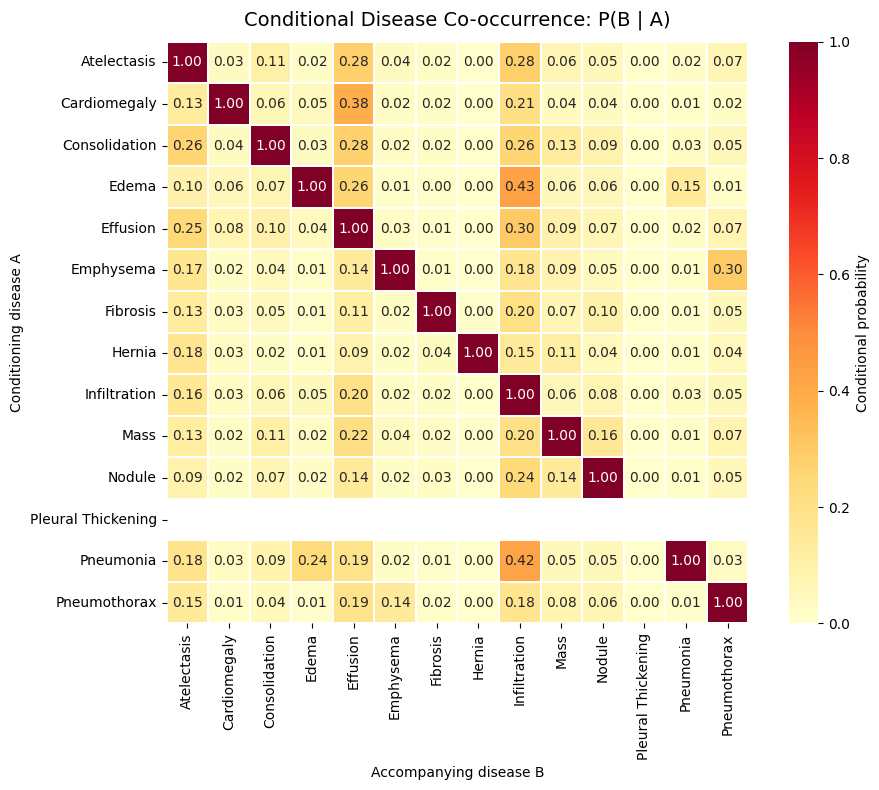

In [ ]:
# CONDITIONAL PROBABILITY HEATMAP
plt.figure(figsize = (10, 8))

sns.heatmap(conditional, cmap = "YlOrRd", vmin = 0, vmax = 1, annot = True, fmt = ".2f", square = True, linewidths = 0.3, cbar_kws = {"label": "Conditional probability"})

plt.title("Conditional Disease Co-occurrence: P(B | A)", fontsize = 14,pad = 12)
plt.xlabel("Accompanying disease B")
plt.ylabel("Conditioning disease A")

plt.xticks(rotation = 90)
plt.yticks(rotation = 0)

plt.tight_layout()
plt.show()

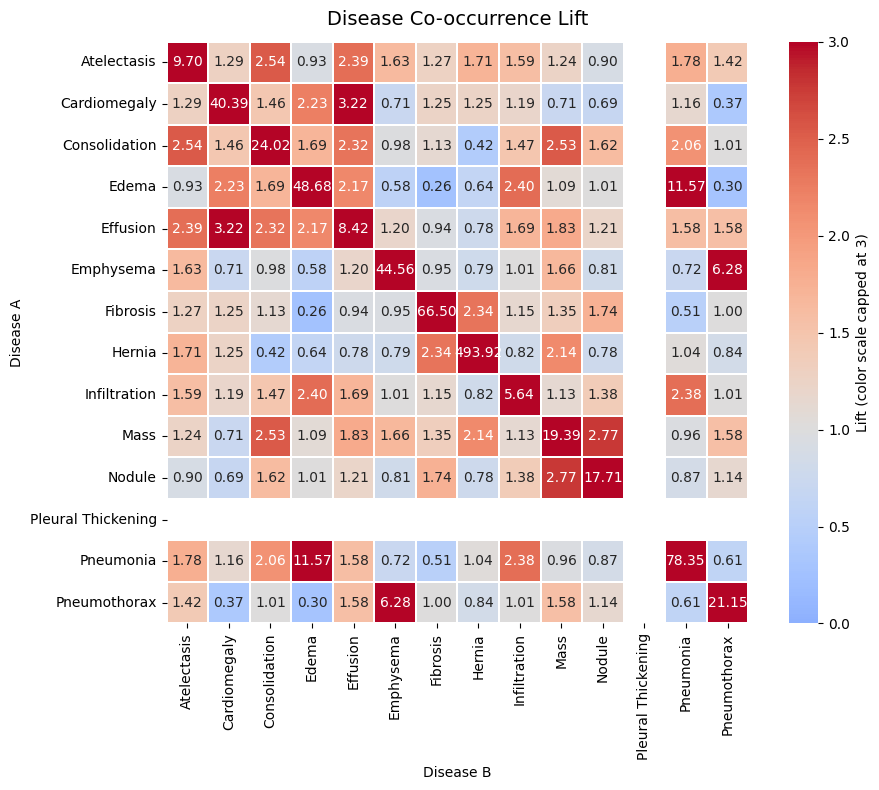

In [ ]:
# DISEASE CO-OCCURRENCE LIFT HEATMAP
plt.figure(figsize = (10, 8))

sns.heatmap(lift, cmap = "coolwarm", center = 1, vmin = 0, vmax = 3, annot = True, fmt = ".2f", square = True, linewidths = 0.3, cbar_kws = {"label": "Lift (color scale capped at 3)"})

plt.title("Disease Co-occurrence Lift", fontsize = 14, pad = 12)
plt.xlabel("Disease B")
plt.ylabel("Disease A")

plt.xticks(rotation = 90)
plt.yticks(rotation = 0)

plt.tight_layout()
plt.show()

In [ ]:
# DISEASE EXCLUSION EVALUATION (function to calculate simple OOD and hybrid OOD counts, evaluate each disease as potential unseen OOD category)
def exclusion_evaluation(binary_matrix, metadata, excluded_diseases, min_known_diseases = 1):
    if isinstance(excluded_diseases, str):                                                    # convert single disease name int list so funct supports both single and multi exclusion
        excluded_diseases = [excluded_diseases]

    exclude = list(dict.fromkeys(excluded_diseases))                                          # remove duplicate names while preserving order

    unknown_names = set(exclude) - set(binary_matrix.columns)

    if unknown_names:
        raise ValueError(f"Diseases not found in binary_matrix: {sorted(unknown_names)}")

    known = [disease for disease in binary_matrix.columns if disease not in exclude]          # all disease not excluded are treated as "known"
    has_exclusion = binary_matrix[exclude].eq(1).any(axis = 1)                                # T for any img containing at least one excluded disease, including imgs that have known labels!

    num_known = binary_matrix[known].sum(axis = 1)                                            # count known disease labels on each img

    hybrid_ood = (has_exclusion & (num_known >= min_known_diseases))                          # at least one excluded disease w/ enough known labels
    simple_ood = (has_exclusion & (num_known == 0))                                           # at least one excluded disease w/ no known labels (e.g., img w/ two excluded diseases & no known falls under this!)

    result = {                                                                                # dict to store img count and unique patient count
        "excluded_diseases": ", ".join(exclude),                                              # disease excluded from known label set
        "excluded_positive_images": int(has_exclusion.sum()),                                 # num of imgs containing excluded disease (indicates overall availability of examples)
        "hybrid_images": int(hybrid_ood.sum()),                                               # num of hybrid OOD imgs (imgs w/ excluded disease and at least one known disease)
        "simple_ood_images": int(simple_ood.sum()),                                           # num of simple OOD imgs (imgs w/ excluded disease and no known diseases)
        "hybrid_unique_patients": int(metadata.loc[hybrid_ood, "Patient ID"].nunique()),      # num of unique patients contributing to hybrid OOD
        "simple_ood_unique_patients": int(metadata.loc[simple_ood, "Patient ID"].nunique())   # num of unique patients contributing to simple OOD
    }

    return result

In [ ]:
# INDIVIDUALLY EVALUATE EACH DISEASE
results = []                                                                                                    # list to store results of exclusion_evaluation()

for disease in binary_matrix.columns:
    result = exclusion_evaluation(binary_matrix = binary_matrix, metadata = df, excluded_diseases = disease)
    results.append(result)

results_df = pd.DataFrame(results)                                                                              # convert list of result dicts into df
results_df = (results_df.sort_values("hybrid_unique_patients", ascending = False).reset_index(drop=True))       # rank diseases by num of unique patients contributing hybrid examples


print("\n" + "=" * 140)
print("EXCLUDED DISEASE EVALUATION RESULTS")
print("=" * 140)

print(results_df.to_string(index = False))


EXCLUDED DISEASE EVALUATION RESULTS
 excluded_diseases  excluded_positive_images  hybrid_images  simple_ood_images  hybrid_unique_patients  simple_ood_unique_patients
      Infiltration                     19894          10137               9757                    4085                        5566
          Effusion                     13317           9111               4206                    3451                        2083
       Atelectasis                     11559           7227               4332                    3410                        2705
            Nodule                      6331           3485               2846                    2002                        1978
              Mass                      5782           3511               2271                    1727                        1435
     Consolidation                      4667           3311               1356                    1649                         876
      Pneumothorax                      5302  

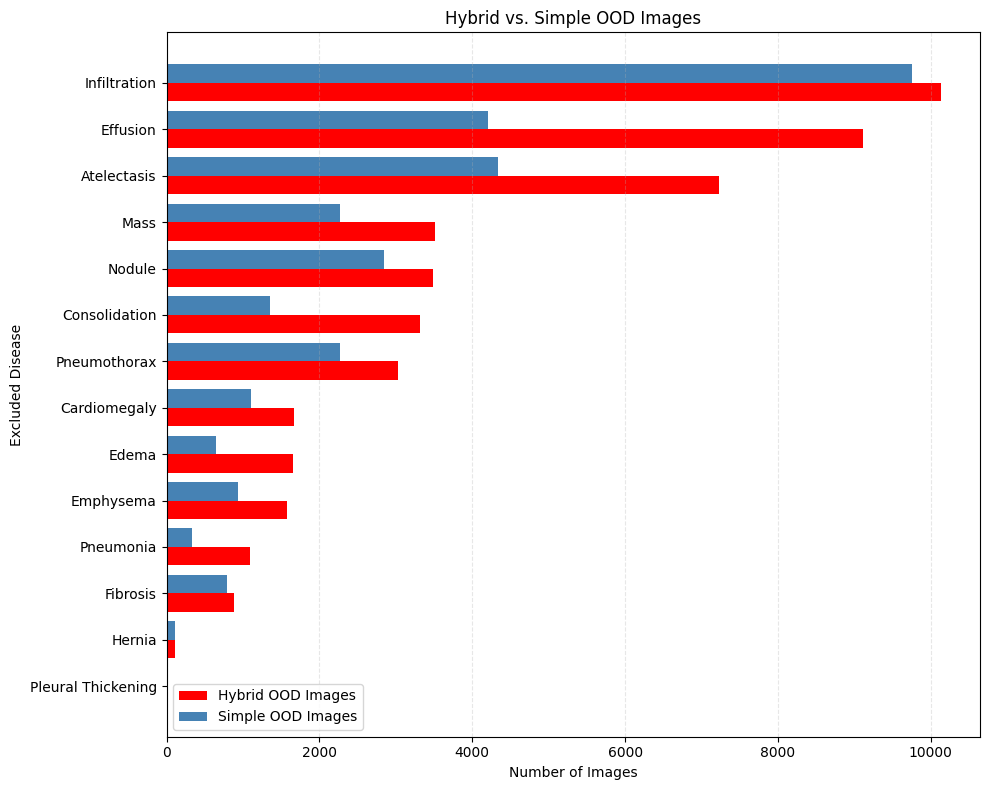

In [ ]:
# COMPARE SIMPLE VS HYBRID OOD IMG COUNTS
plot_df = results_df.sort_values("hybrid_images", ascending = True).copy()          # sort diseases by hybrid OOD img count

y = np.arange(len(plot_df))                                                         # horizontal grouped bars
bar_height = 0.4

fig, ax = plt.subplots(figsize = (10, 8))

ax.barh(y - bar_height/2, plot_df["hybrid_images"], height = bar_height, label = "Hybrid OOD Images", color = "red")
ax.barh(y + bar_height/2, plot_df["simple_ood_images"], height = bar_height, label = "Simple OOD Images", color = "steelblue")

ax.set_yticks(y)
ax.set_yticklabels(plot_df["excluded_diseases"])

ax.set_xlabel("Number of Images")
ax.set_ylabel("Excluded Disease")
ax.set_title("Hybrid vs. Simple OOD Images")

ax.legend()
ax.grid(axis = "x", linestyle = "--", alpha = 0.3)

plt.tight_layout()
plt.show()

# NOTES: large hybrid count = more imgs where excluded disease co-occurs w/ at least one known disease, large simple count = more imgs w/o any known disease labels,
        # large count for both = useful for comparing simple and hybrid detection under same excluded disease

## **Data Exploration Notes**
---
***Columns:*** Image Index, Finding Labels, Follow-up #, Patient ID, Patient Age, Patient Gender, View Position, OriginalImage[Width, Height], OriginalImagePixelSpacing[x', 'y], Unnamed: 11

***Number of Unique Patients:*** 30,805

***Labels in Dataset:*** Atelectasis, Cardiomegaly, Consolidation, Edema, Effusion, Emphysema, Fibrosis, Hernia, Infiltration, Mass, No Finding, Nodule, Pleural Thickening, Pneumonia, Pneomothorax

***Number of "No Finding" Images:*** 60,361 (~54% of dataset)

***Number of Images with 2 or More Diseases:*** 20,646

---

Extreme class imbalance between disease labels.

Note that when counting the number of diseases per image, these are NOT mutually exclusive categories. So, for example, an image containing Effusion + Atelectasis counts to both disease labels, so percent will not add up to 100.

The official split for this dataset has a combined train + validation, not separate training and validation splits. For paper, need to explicitly document how we are handling the split to avoid concerns of patient overlap. (Patient leakage/overlap is important because the same patient can have multiple disease images!)
- A patient-level train/test split should solve this leakage problem, but it does not ensure that disese distribution is balanced across train/validation.
- When splitting dataset, want to preserve patient separation and distribution of multiple disease labels.

---

Select in-distribution diseases based on things like frequency, co-occurence patterns, and clinical relevance.

Simple OOD can test whether detector recognizes unfamilar pathology in the absence of familar disease signal, and hybrid OOD can test whether a model's cofident recognition of a known disease masks the evidence of an unknown one.

Choose to exclude a disease based on co-occurence, i.e., choose a pathology that frequently overlaps w/ retained ID diseases. However, it could be difficult to distinguish an unknown disease's contribution from a known disease's contribution. Essentially, want a sufficient overlap w/o making the experiment trivially easy or impossible.

Could also choose to exclude a rarer disease for a simple initial experiment, but this may yield too few hybrid examples.

***Choose which disease to exclude based on:***
1. *Sufficient number of hybrid OOD examples* (need enough images containing the exlcuded disease alongside at least one known disease to reliably evaluate detection). avoid disease with very few hybrid examples because this can make OOD performance estimates unstable, so aim to choose a disease with substantial counts across many patients.

2. *Both simple OOD and hybrid OOD examples.* If we plan compare how this detector behaves on simple vs. hybrid OOD, same excluded disease should ideally provide enough examples of both.

3. *Meaningful co-occurrence with known diseases.* Use conditional probability and lift matrix to see which known disease tend to accompany each possible excluded disease. Conditional probability tells use how frequently a known disease accompanies the excluded disease. Lift tells us whether co-occurrence is stronger or weaker than expected from the diseases' individual frequencies. Do NOT select based on lift alone, as a very high life could result from a small number of examples. Want to choose to exclude a disease with many hybrid examples involving common, well-represented known diseases.

4. *Sufficient representation and reliable labels.* Rare disease might only have a few positive examples and unstable evaluation results. Common diseases can be useful if they have plenty of hybrid examples. Examine: total positive images, hybrid and simple OOD counts, and unique patients in each group to determine a meaningful sample.

---

**Diseases to Excluded Based on Results**

Best choice depends on what we want to prioritize: sample size, balanced comparison between simple and hybrid OOD, etc.

1. ***Effusion:*** 13,317 positive images, 3,451 hybrid patients
    - Hybrid OOD: 9,111 images
    - Simple OOD: 4,206 images
    - Offers substantial number of examples in both OOD settings, broad patient coverage, but check which known diseases dominate its hybrid cases

2. ***Atelectasis:*** 11,559 positive images, 3,410 hybrid patients
    - Hybrid OOD: 7,227 images
    - Simple OOD: 4,332 images
    - Good patient coverage and relatively balanced number of hybrid and simple OOD examples, good if we want to compare simple and hybrid w/o one category being overwhelmingly larger than the other
    - However, should check whether any co-occuring labels are "dominating"

3. ***Pneumothorax:*** 5,302 positive images, 1,049 hybrid patients
    - Hybrid OOD: 3,029 images
    - Simple OOD: 2,273 images
    - Relatively balanced simple vs. hybrid sample size, but fewer hybrid patients than other diseases

4. ***Infiltration:***
    - Largest and most balanced candidate pool/evaluation set, broad, but potentially ambigious label
    - Strong candidate if we want to prioritize maximizing sample size and balancing two OOD settings


If primary goal is a balanced simple vs. hybrid comparison, then should likely choose ***Atelectasis*** or ***Pneumothorax.***